# Lab 3: Working with Real Climate Data
------
## Analyze data in the format of data frame 

1. Climate data for Texas, South, and Central region
2. Read, save, and manipulate data frame with pandas pacakage
3. Calculate simple descriptive statistics 
4. Learn correlation between variables
5. Plot with seaborn package


Lab TA: Lee Ochs

In [2]:
#load the correct environment/kernel (python 3 ipykernel)
#mine uses the base enviornment 
#if package does not load correctly, close notebook, type "conda activate base" in ur terminal, then type "jupyter notebook"
import pandas as pd #data frame
import numpy as np  #matrix, numbers 
import matplotlib.pyplot as plt
from scipy.stats import binom, poisson
import seaborn as sns

### Introduction to Climate Variables
In this lab, we will use time series datasets from NOAA's National Climate Data Center, which includes several climate indicators such as:
- Precipitation (inches)
- Temperature (degrees Fahrenheit)
- Cooling Degree Days (CDD)
- Heating degree days (HDD)
- Palmer drought indices
    - Palmer Z Index (ZNDX)
    - Palmer Drought Severity Index (PDSI)
    - Palmer Modified Drought Index (PMDI)
    - Palmer Hydrological Drought Index (PHDI)

Read more about these indices from the following webpages:
- [Cooling and Heating Degree Days](https://www.cpc.ncep.noaa.gov/pacdir/DDdir/INT1.html)
- [Historical Palmer Drought Indices](https://www.ncei.noaa.gov/access/monitoring/historical-palmers/overview)
-	Heim, Jr., Richard R., 2002: A review of Twentieth-Century drought indices used in the United States. Bulletin of the American Meteorological Society, vol. 83, pp. 1149- 1165. (Paper attached in the lab assginment for download, this is needed for your lab 3)

Data is stored in the form of data frame\
More [tutorial]{https://pandas.pydata.org/docs/getting_started/intro_tutorials/01_table_oriented.html }\
We have three datasets\
Texas, south, southcentral (see slides)\
They have the same format

In [3]:
#read the data and save as a named data frame
'''
#df_tx = pd.read_csv('texas_2006_2015.txt', sep='\s+')
df_tx = pd.read_csv('/home/noahr/pythonProjects/OCNG470/Lab3/texas_2006_2015-1.txt', sep='\s+')
type(df_tx)  #check the type of the object; print it
df_tx.head(10)
#practise, read the data for the south and save it to df_st
df_st = pd.read_csv('/home/noahr/pythonProjects/OCNG470/Lab3/south_2006_2015-2.txt', sep='\s+')
#practise, read the data for the southcentral and save it to df_sc
df_sc = pd.read_csv('/home/noahr/pythonProjects/OCNG470/Lab3/southcentraltexas_2006_2015.txt', sep='\s+')
'''
### Filepaths on my desktop
df_tx = pd.read_csv(r'C:\Users\noahr\Documents\Python Scripts\OCNG470\Lab3\texas_2006_2015-1.txt', sep=r'\s+')
df_st = pd.read_csv(r'C:\Users\noahr\Documents\Python Scripts\OCNG470\Lab3\south_2006_2015-2.txt', sep=r'\s+')
df_sc = pd.read_csv(r'C:\Users\noahr\Documents\Python Scripts\OCNG470\Lab3\southcentraltexas_2006_2015.txt', sep=r'\s+')

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
C:\Users\noahr\AppData\Local\Temp\ipykernel_104552\889852800.py:2: SyntaxWarning: invalid escape sequence '\s'
  '''


In [4]:
# See the first few rows of the DataFrame
print(df_tx.head())
# Check columns and data types
print(df_tx.info())
# Quickly see statistics (mean, std, min, max, etc.) for numeric columns
print(df_tx.describe())

   StateCode  Division  YearMonth   PCP  TAVG  PDSI  PHDI  ZNDX  PMDI  CDD  \
0         41         0     200601  1.06  52.9 -3.21 -3.21 -2.54 -3.21   38   
1         41         0     200602  1.14  50.3 -3.56 -3.56 -2.03 -3.56   13   
2         41         0     200603  2.07  61.1 -3.43 -3.43 -0.72 -3.43  103   
3         41         0     200604  1.51  70.7 -4.11 -4.11 -3.10 -4.11  231   
4         41         0     200605  2.20  75.7 -4.96 -4.96 -3.81 -4.96  349   

   HDD  SP01  SP02  SP03  SP06  SP09  SP12  SP24  TMIN  TMAX  
0  328 -0.43 -1.37 -1.52 -1.11 -1.21 -1.16  0.81  37.5  68.3  
1  369 -0.46 -0.61 -1.27 -1.62 -1.26 -1.46  0.62  36.3  64.2  
2  147  0.48 -0.01 -0.24 -0.94 -0.79 -1.39  0.60  48.7  73.5  
3   14 -0.59 -0.09 -0.33 -1.16 -1.11 -1.24  0.29  57.0  84.4  
4    0 -0.82 -1.07 -0.63 -1.21 -1.54 -1.36  0.28  62.2  89.3  
<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 20 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     ---

In [5]:
#select a column
df_tx['PDSI']
#others ways to select a column
#df_tx.iloc[:,3]
#select a row
#df_tx.iloc[0,:]

#you can save it as a variable
#tx_pdsi = df_tx['PDSI']


#practise, select the column for the year and month, save it as a variable

0     -3.21
1     -3.56
2     -3.43
3     -4.11
4     -4.96
       ... 
115    4.19
116    2.81
117    3.85
118    4.62
119    4.84
Name: PDSI, Length: 120, dtype: float64

In [6]:
#calculate some statistics
df_tx['PDSI'].mean()
df_tx['TAVG'].median()
df_tx['PCP'].std()
df_tx['PCP'].mode()
#remember to use parentheses for functions
#remember to print if you want to see the output of everyone
#here it only shows the output of the last line if no print is used
#mode has two values, access one of them like a list

0    1.87
1    2.29
Name: PCP, dtype: float64

Pandas package have many functions to manipulate data frame
See it here: https://pandas.pydata.org/docs/getting_started/intro_tutorials/06_calculate_statistics.html

In [7]:
#save it as a named variable so it is easier to call
# Mean
mean = df_tx['PDSI'].mean()

#practise, calculate and save the median, mode, and standard deviation of the PDSI column for Texas


In [9]:

#use pd.to_datetime function to convert the YearMonth column
#practise fill in the code by creating a new column "Date" from "YearMonth"
df_tx['Date'] = pd.to_datetime(df_tx['YearMonth'], format='%Y%m')
df_st['Date'] = pd.to_datetime(df_st['YearMonth'], format='%Y%m')
df_sc['Date'] = pd.to_datetime(df_sc['YearMonth'], format='%Y%m')

We still wanna see the results\
Lets plot precipitation over time using a new package [seaborn]{https://seaborn.pydata.org/tutorial/function_overview.html}

sns.lineplot(x = '', y = '', data=, label='', color='')

Lineplot is one of the many plots
In Lab 3, we will use sns.lineplot, sns.histplot, and sns.scatterplot

C:\Users\noahr\AppData\Local\Temp\ipykernel_104552\2989827599.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


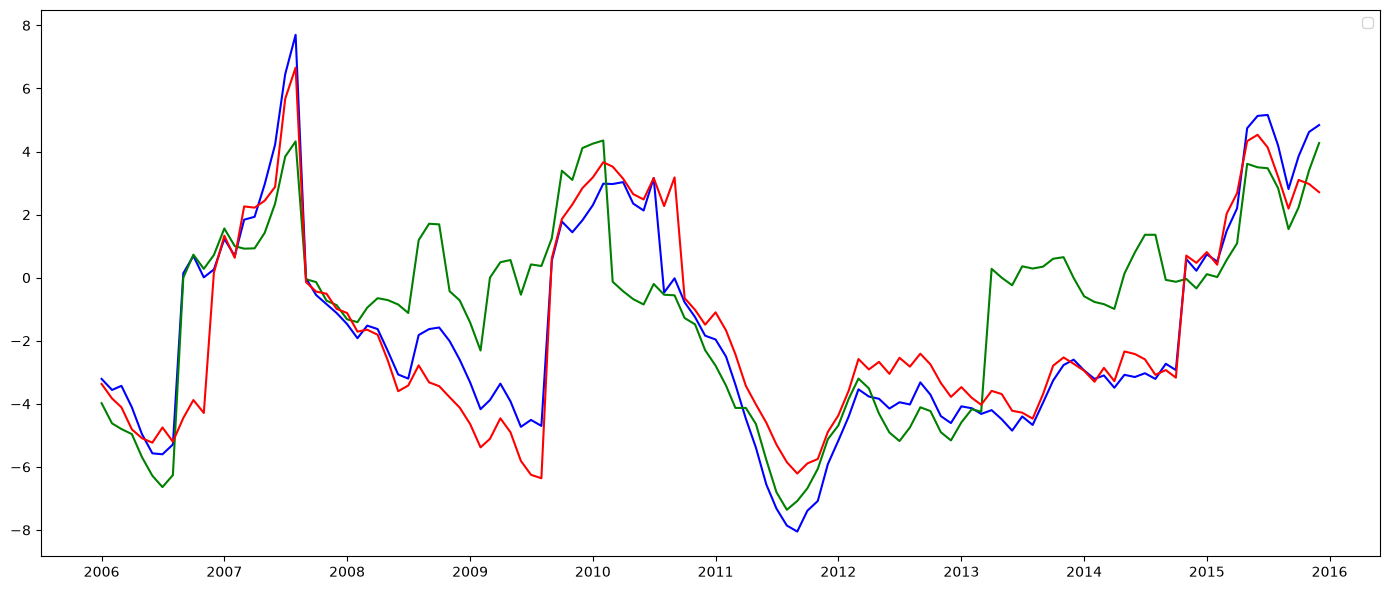

In [10]:

#create canva, specify canvas size
plt.figure(figsize=(14, 6))

#Practise fill in the code to plot PDSI over for Texas, label and color it
sns.lineplot(x = 'Date', y='PDSI', data=df_tx, label='', color='b')
sns.lineplot(x = 'Date', y='PDSI', data=df_st, label='', color='g')
sns.lineplot(x = 'Date', y='PDSI', data=df_sc, label='', color='r')
plt.xlabel('')
plt.ylabel('')
plt.title('')
plt.legend()

#show the data
plt.tight_layout()
plt.show()

#the date is weird
#the year month is not in a date format but in interger format 
#it does not know 200601 is year 2006 and Jan, but it think it is a number


In [ ]:
#we can add more lines to the same plot
#Practise fill in the code to plot PDSI for south, label and color it, color it differently

We suspect  sometimes it rains more sometimes it rains less\
What is the overall rainfall distribution?\
Lets use histagram to visulize the rainfall from all areas

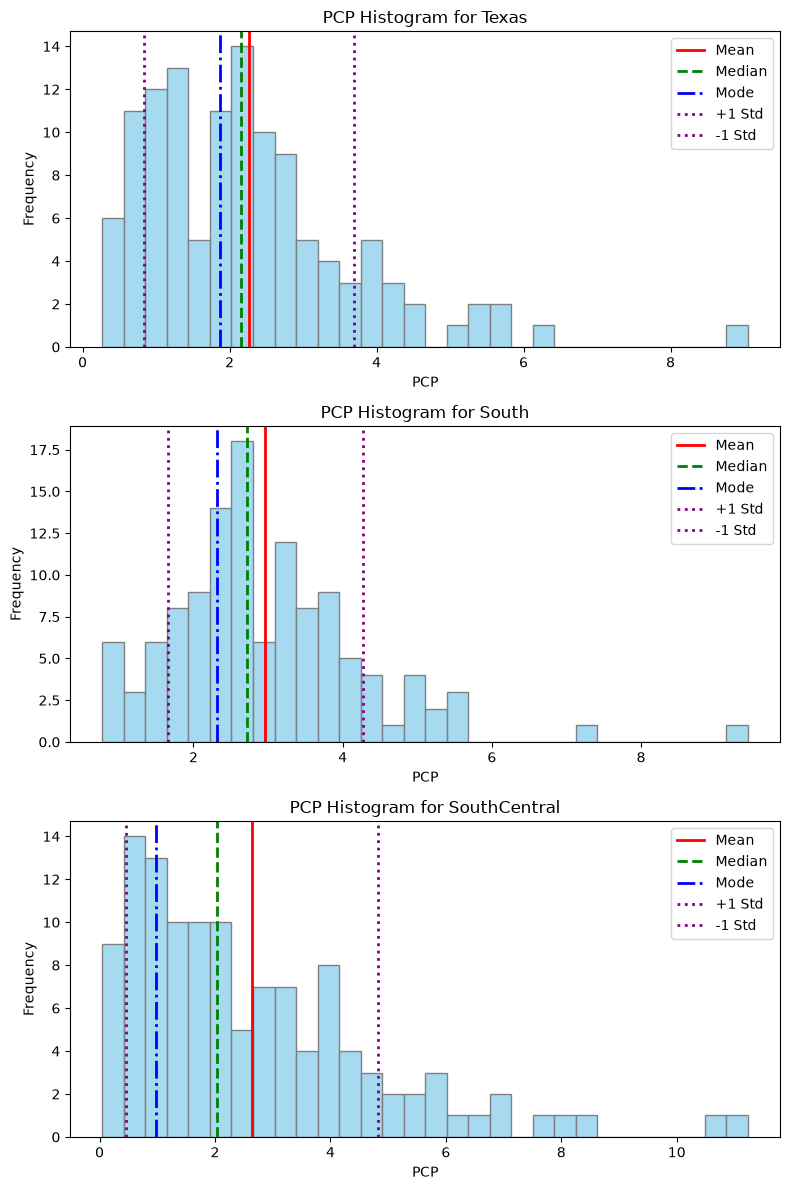

In [11]:
#visualize the distribution of precipitation for texas, south, and southcentral in each subplot
#we can add vertical lines to show mean, median, mode, and standard deviation
#use ax1 ax2 ax3 to specify each figure
#us ax1.axvline(number, color, linestyle, linewidth, label)

plt.figure(figsize=(8, 12))

# --- Texas ---
ax1 = plt.subplot(3, 1, 1)
sns.histplot(df_tx['PCP'], bins=30, color='skyblue', edgecolor='gray', ax=ax1)
mean = df_tx['PCP'].mean()
median = df_tx['PCP'].median()
mode = df_tx['PCP'].mode()[0]
std = df_tx['PCP'].std()
ax1.axvline(mean, color='red', linestyle='-', linewidth=2, label='Mean')
ax1.axvline(median, color='green', linestyle='--', linewidth=2, label='Median')
ax1.axvline(mode, color='blue', linestyle='-.', linewidth=2, label='Mode')
ax1.axvline(mean+std, color='purple', linestyle=':', linewidth=2, label='+1 Std')
ax1.axvline(mean-std, color='purple', linestyle=':', linewidth=2, label='-1 Std')
ax1.set_title("PCP Histogram for Texas")
ax1.set_xlabel("PCP")
ax1.set_ylabel("Frequency")
ax1.legend()

# --- South ---
ax2 = plt.subplot(3, 1, 2)
sns.histplot(df_st['PCP'], bins=30, color='skyblue', edgecolor='gray', ax=ax2)
mean = df_st['PCP'].mean()
median = df_st['PCP'].median()
mode = df_st['PCP'].mode()[0]
std = df_st['PCP'].std()
ax2.axvline(mean, color='red', linestyle='-', linewidth=2, label='Mean')
ax2.axvline(median, color='green', linestyle='--', linewidth=2, label='Median')
ax2.axvline(mode, color='blue', linestyle='-.', linewidth=2, label='Mode')
ax2.axvline(mean+std, color='purple', linestyle=':', linewidth=2, label='+1 Std')
ax2.axvline(mean-std, color='purple', linestyle=':', linewidth=2, label='-1 Std')
ax2.set_title("PCP Histogram for South")
ax2.set_xlabel("PCP")
ax2.set_ylabel("Frequency")
ax2.legend()


ax3 = plt.subplot(3, 1, 3)
sns.histplot(df_sc['PCP'], bins=30, color='skyblue', edgecolor='gray', ax=ax3)
mean = df_sc['PCP'].mean()
median = df_sc['PCP'].median()
mode = df_sc['PCP'].mode()[0]
std = df_sc['PCP'].std()
ax3.axvline(mean, color='red', linestyle='-', linewidth=2, label='Mean')
ax3.axvline(median, color='green', linestyle='--', linewidth=2, label='Median')
ax3.axvline(mode, color='blue', linestyle='-.', linewidth=2, label='Mode')
ax3.axvline(mean+std, color='purple', linestyle=':', linewidth=2, label='+1 Std')
ax3.axvline(mean-std, color='purple', linestyle=':', linewidth=2, label='-1 Std')
ax3.set_title("PCP Histogram for SouthCentral")
ax3.set_xlabel("PCP")
ax3.set_ylabel("Frequency")
ax3.legend()


plt.tight_layout()
plt.show()

#practise: fill in the code to plot the histogram for south and southcentral too

some of the data seems to have a similar distribution
Do they change according to each other
We can simply plot south against texas with scatter plot to check 

Text(0.5, 1.0, 'South vs Texas PDSI')

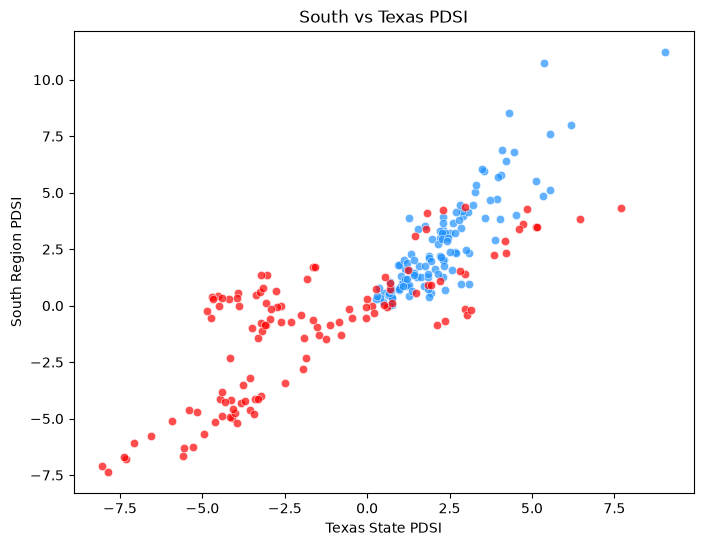

In [17]:
#scatter plot to see the relationship between Texas and South PDSI
#make sure the label is ok
plt.figure(figsize=(8, 6))
#here we dont have to call the entire data, if we specify that data when we call x and y
sns.scatterplot(x=df_tx['PCP'], y=df_sc['PCP'], color='dodgerblue', alpha=0.7)

#Practise: add another relationship, by plotting scatter plot between PDSI form south vs PDSI from southcentral
#change the label and color accordingly
sns.scatterplot(x=df_tx['PDSI'], y=df_st['PDSI'], color='r', alpha=0.7)
plt.xlabel("Texas State PDSI")
plt.ylabel("South Region PDSI")
plt.title("South vs Texas PDSI")

In [13]:
#some looks correlated but some not so, lets use a number to quantify how correlated they are!
#functions from pd.

from scipy.stats import pearsonr
#pearsonr(data 1, data 2)
#it return a correlation coeffcient and a p value
results = pearsonr(df_tx['PCP'], df_sc['PCP'])
results
#Practise use the function to caculate the correlation between PDSI from texas vs from south

#then save it to a named variable
#access the correlation and p value 

PearsonRResult(statistic=np.float64(0.8796848591891123), pvalue=np.float64(6.754834043961813e-40))